EXPERIMENT NO. 7 (Group B) 
 
Aim: Interacting with Web APIs 
Problem Statement: Analyzing Weather Data from OpenWeatherMap API 
Dataset: Weather data retrieved from OpenWeatherMap API



Name:Aditya Rade
Roll.No:BEAD23167

Outputs:


Step - Retrieve Weather Data

In [48]:
import os
import requests
import pandas as pd

api_key = os.environ.get("OPENWEATHER_API_KEY")
if not api_key:
    raise RuntimeError("Set the OPENWEATHER_API_KEY environment variable before running this cell.")

# Coordinates for Pune
lat = 18.184135
lon = 74.610764

# API URL
api_url = (
    f"https://api.openweathermap.org/data/2.5/forecast"
    f"?lat={lat}&lon={lon}&appid={api_key}"
)

# Send request
response = requests.get(api_url)

print("Status Code:", response.status_code)

weather_data = response.json()

# Check whether the request was successful
if response.status_code != 200:
    print("Error:", weather_data)
else:
    print(weather_data.keys())
    print(weather_data["list"][0])

Status Code: 200
dict_keys(['cod', 'message', 'cnt', 'list', 'city'])
{'dt': 1791309600, 'main': {'temp': 300.04, 'feels_like': 300.52, 'temp_min': 300.04, 'temp_max': 300.04, 'pressure': 1014, 'sea_level': 1014, 'grnd_level': 951, 'humidity': 51, 'temp_kf': 0, 'dew_point': 289.06}, 'weather': [{'id': 802, 'main': 'Clouds', 'description': 'scattered clouds', 'icon': '03n'}], 'clouds': {'all': 41}, 'wind': {'speed': 1.23, 'deg': 339, 'gust': 2.43}, 'visibility': 10000, 'pop': 0, 'sys': {'pod': 'n'}, 'dt_txt': '2026-10-06 18:00:00'}


Step 2- Extract Weather Data

In [49]:
timestamps = [
    pd.to_datetime(item["dt"], unit="s")
    for item in weather_data["list"]
]

temperature = [
    item["main"]["temp"]
    for item in weather_data["list"]
]

humidity = [
    item["main"]["humidity"]
    for item in weather_data["list"]
]

wind_speed = [
    item["wind"]["speed"]
    for item in weather_data["list"]
]

weather_desc = [
    item["weather"][0]["description"]
    for item in weather_data["list"]
]

# Create DataFrame
weather_df = pd.DataFrame({
    "Timestamp": timestamps,
    "Temperature": temperature,
    "humidity": humidity,
    "wind_speed": wind_speed,
    "weather_description": weather_desc
})

# Set Timestamp as index
weather_df.set_index("Timestamp", inplace=True)

# Display first 5 records
weather_df.head()

,Temperature,humidity,wind_speed,weather_description
Timestamp,,,,
2026-10-06 18:00:00,300.04,51,1.23,scattered clouds
2026-10-06 21:00:00,299.78,50,2.68,scattered clouds
2026-10-07 00:00:00,298.45,48,2.41,few clouds
2026-10-07 03:00:00,300.77,40,3.34,clear sky
2026-10-07 06:00:00,305.87,28,4.65,clear sky


Step 3 — Clean Data and Convert Temperature

In [50]:
# Handle missing values
weather_df.fillna(0, inplace=True)

# Convert Kelvin to Celsius
weather_df["Temperature"] = weather_df["Temperature"] - 273.15

# Find maximum and minimum temperature
print("Max Temp (°C):", weather_df["Temperature"].max())
print("Min Temp (°C):", weather_df["Temperature"].min())

# Display the data
weather_df

Max Temp (°C): 35.34000000000003
Min Temp (°C): 25.100000000000023


,Temperature,humidity,wind_speed,weather_description
Timestamp,,,,
2026-10-06 18:00:00,26.89,51,1.23,scattered clouds
2026-10-06 21:00:00,26.63,50,2.68,scattered clouds
2026-10-07 00:00:00,25.30,48,2.41,few clouds
2026-10-07 03:00:00,27.62,40,3.34,clear sky
2026-10-07 06:00:00,32.72,28,4.65,clear sky
2026-10-07 09:00:00,34.27,23,4.26,clear sky
2026-10-07 12:00:00,34.50,23,3.82,clear sky
2026-10-07 15:00:00,30.80,28,5.79,overcast clouds
2026-10-07 18:00:00,28.35,38,4.54,overcast clouds


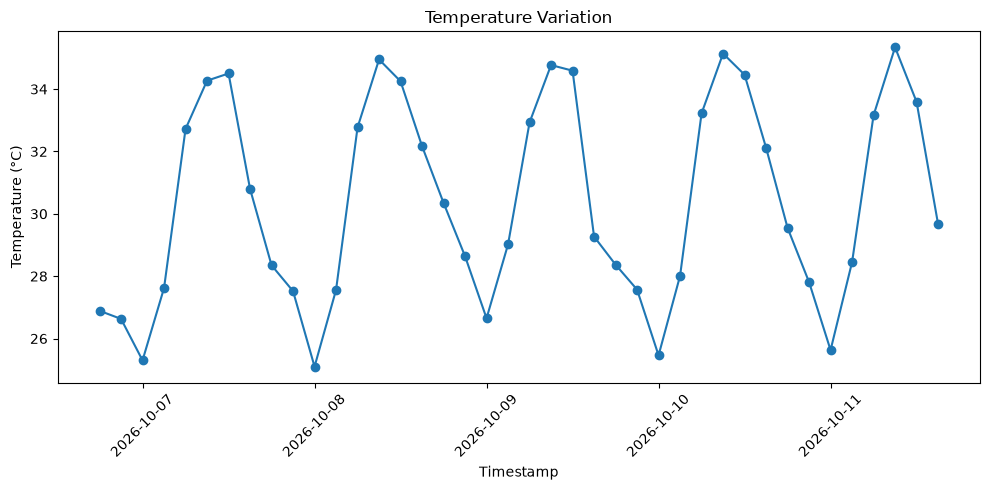

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    weather_df.index,
    weather_df["Temperature"],
    marker="o"
)

plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Variation")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [54]:
import folium

weather_map = folium.Map(
    location=[50.5, 1.5],
    zoom_start=5
)

# London marker
folium.Marker(
    [51.5074, -0.1278],
    popup=folium.Popup(
        """
        <b>London</b><br>
        Temperature: 21.7°C<br>
        Humidity: 46%
        """,
        max_width=200
    ),
    tooltip="London",
    icon=folium.Icon(color="red", icon="cloud")
).add_to(weather_map)

# Paris marker
folium.Marker(
    [48.8566, 2.3522],
    popup=folium.Popup(
        """
        <b>Paris:</b><br>
        21.7°C,<br>
        Humidity<br>
        46%
        """,
        max_width=150
    ),
    tooltip="Paris",
    icon=folium.Icon(color="red", icon="cloud")
).add_to(weather_map)

# Save
weather_map.save("weather_map.html")

print("Weather map created successfully!")
print("Name:Aditya Rade Roll No:BEAD23167")

Weather map created successfully!
Name:Aditya Rade Roll No:BEAD23167
